<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(2000, 21)


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,price_range
0,0.262426,0.669708,-1.931278,-3.090252,0.772400,-0.275264,-0.133019,-2.773861,2.839263,0.673275,...,0.524092,-9.309327,1.391899,-0.603114,-4.721735,-0.426238,-0.631626,3.727833,0.106689,1
1,0.379160,0.554511,-1.194104,-1.109284,-0.223590,-3.279604,0.955416,-1.956375,0.724699,-1.772399,...,-1.661832,-2.241012,-2.302543,0.182083,-2.818850,2.159566,-1.032919,-0.047753,-0.793103,1
2,0.041751,-3.280898,0.403685,4.049369,-0.118336,-1.335420,-0.057961,-3.259883,4.879932,2.445939,...,-0.370171,-1.063373,0.316113,-0.989131,-3.482135,1.219599,-3.486848,-0.179673,0.501604,3
3,-1.174222,0.032599,0.571324,3.467358,-0.246859,-1.824900,0.763748,0.118426,2.493471,-1.395898,...,-5.583381,2.281817,-3.513425,0.419217,0.417312,-2.387808,-0.200310,1.579719,-0.300404,1
4,0.658037,-2.291064,4.379164,4.239263,-1.134391,-0.373807,-1.130474,3.243908,-3.345175,-0.769165,...,-2.464425,6.837423,-1.179979,1.688407,1.588278,3.325861,-1.491913,-0.410362,-1.216067,2


Accuracy: 0.78
              precision    recall  f1-score   support

           0       0.69      0.79      0.74        99
           1       0.78      0.78      0.78       101
           2       0.85      0.83      0.84       100
           3       0.82      0.72      0.77       100

    accuracy                           0.78       400
   macro avg       0.78      0.78      0.78       400
weighted avg       0.78      0.78      0.78       400



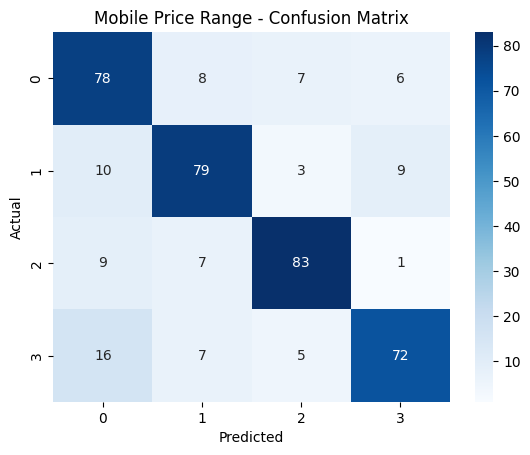

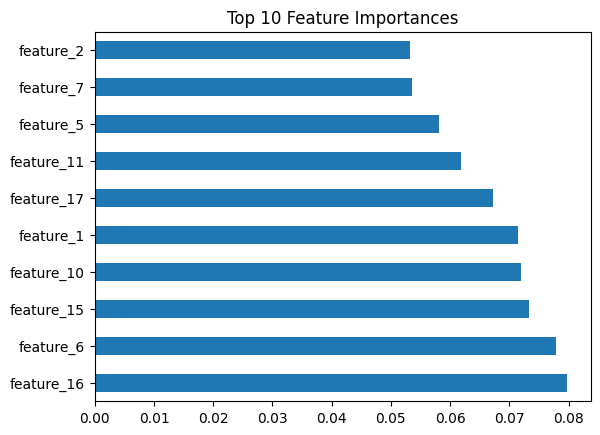

In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# from google.colab import files; files.upload()   # uncomment to upload train.csv
if os.path.exists("train.csv"):
    df = pd.read_csv("train.csv")
else:
    from sklearn.datasets import make_classification
    X_, y_ = make_classification(n_samples=2000, n_features=20, n_informative=12,
                                 n_classes=4, random_state=42)
    df = pd.DataFrame(X_, columns=[f"feature_{i}" for i in range(20)])
    df["price_range"] = y_

print(df.shape); display(df.head())
X = df.drop("price_range", axis=1); y = df["price_range"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=200, random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred))
sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues")
plt.title("Mobile Price Range - Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

imp = pd.Series(model.feature_importances_, index=X.columns).nlargest(10)
imp.plot(kind="barh", title="Top 10 Feature Importances"); plt.show()